# Trabalho G2 — Ciência de Dados

**Problema:** Classificação binária do meio de pagamento em feiras (`dataset.csv`) — prever **`pagamento_digital`** (`1` = Cartão/PIX, `0` = Dinheiro) para apoiar o planejamento de troco, maquininhas e internet.

**Escopo:**
1. **Pré-processamento e Engenharia de Recursos:** limpeza, criação de variáveis, técnicas da aula e `Pipeline` + `ColumnTransformer` (sem *data leakage*).
2. **Modelagem e Avaliação:** split 80/20, baselines, `StratifiedKFold(5)` + `GridSearchCV` (4 modelos), avaliação no teste, **Nested CV (IC 95%)**, **SHAP** e `joblib`.

## Etapa 1 — Carregamento, Inspeção e Limpeza

Carregamento do `dataset.csv` bruto (1 linha por item vendido) e correção dos ruídos de caixa.

In [1]:
import re
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

df_raw = pd.read_csv("dataset.csv")

print(f"Dimensões brutas: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print(f"Pedidos únicos  : {df_raw['pedido_id'].nunique()}")
print("\n--- Estrutura (.info) ---")
df_raw.info()

print("\n--- Valores nulos por coluna ---")
display(df_raw.isnull().sum().to_frame("nulos"))

print("\n--- Resumo estatístico (numéricas) ---")
display(df_raw.describe().round(2))

Dimensões brutas: 3815 linhas x 13 colunas
Pedidos únicos  : 3003

--- Estrutura (.info) ---
<class 'pandas.DataFrame'>
RangeIndex: 3815 entries, 0 to 3814
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   pedido_id                   3815 non-null   str    
 1   pedido_valor_total          3815 non-null   float64
 2   pedido_data                 3815 non-null   str    
 3   pedido_tipo_desconto        3815 non-null   str    
 4   pedido_valor_desconto       3815 non-null   float64
 5   pedido_subtotal             3815 non-null   int64  
 6   pedido_vendedor             3814 non-null   str    
 7   pedido_metodo_pagamento     3815 non-null   str    
 8   item_pedido_nome_produto    3815 non-null   str    
 9   item_pedido_quantidade      3815 non-null   int64  
 10  item_pedido_preco_unitario  3815 non-null   float64
 11  item_pedido_user_id         3814 non-null   str    
 12  evento_n

,nulos
pedido_id,0
pedido_valor_total,0
pedido_data,0
pedido_tipo_desconto,0
pedido_valor_desconto,0
pedido_subtotal,0
pedido_vendedor,1
pedido_metodo_pagamento,0
item_pedido_nome_produto,0
item_pedido_quantidade,0



--- Resumo estatístico (numéricas) ---


,pedido_valor_total,pedido_valor_desconto,pedido_subtotal,item_pedido_quantidade,item_pedido_preco_unitario
count,3815.00,3815.00,3815.00,3815.00,3815.00
mean,44.62,0.85,45.48,2.52,13.88
std,190.28,21.10,191.62,7.73,9.18
min,0.00,0.00,5.00,0.00,4.00
25%,15.00,0.00,15.00,1.00,6.00
50%,25.00,0.00,25.00,1.00,10.00
75%,40.00,0.00,40.00,2.00,25.00
max,3693.00,915.00,3696.00,348.00,80.00


### 1.1 Colunas irrelevantes, descontos e itens cancelados

- Remove `pedido_vendedor` e `item_pedido_user_id` (apenas 2 logins de caixa + único `NaN`).
- Valida `100%` dos descontos em R$ (`assert`) e remove `pedido_tipo_desconto`.
- Remove `2` itens cancelados com `quantidade <= 0` (`3.815 -> 3.813` linhas).

In [2]:
df = df_raw.copy()

# 1. Confirmar redundância e remover colunas de login genérico de caixa
assert (df["pedido_vendedor"].fillna("NA") == df["item_pedido_user_id"].fillna("NA")).all()
df = df.drop(columns=["pedido_vendedor", "item_pedido_user_id"])

# 2. Validar matematicamente que 100% dos descontos já estão em moeda (R$)
erro_desconto = (df["pedido_subtotal"] - df["pedido_valor_desconto"] - df["pedido_valor_total"]).abs()
assert (erro_desconto < 0.01).all(), "Há divergência na conta de descontos!"
print(f"Auditoria de descontos OK — erro máximo: R$ {erro_desconto.max():.6f} (100% em R$).")
df = df.drop(columns=["pedido_tipo_desconto"])

# 3. Remover itens com quantidade não positiva (itens cancelados)
n_antes = len(df)
df = df[df["item_pedido_quantidade"] > 0].copy()
n_removidos = n_antes - len(df)

assert n_removidos == 2
assert len(df) == 3813
assert df["pedido_id"].nunique() == 3003

print(f"Itens com qtd <= 0 removidos: {n_removidos} | Base atual: {len(df)} linhas e {df['pedido_id'].nunique()} pedidos.")

Auditoria de descontos OK — erro máximo: R$ 0.000000 (100% em R$).
Itens com qtd <= 0 removidos: 2 | Base atual: 3813 linhas e 3003 pedidos.


### 1.2 Padronização de textos, feiras e pagamentos

- Limpa espaços extras em produtos e eventos.
- Unifica `"1 Moranguinho"` + `"2-Moranguinho"` $\rightarrow$ `"Festa do Moranguinho"`.
- Agrupa pagamentos em `pagamento_grupo`: `Dinheiro`, `Cartão` e `PIX`.

In [3]:
def normalizar_texto(texto: str) -> str:
    return re.sub(r"\s+", " ", str(texto)).strip()

df["item_pedido_nome_produto"] = df["item_pedido_nome_produto"].apply(normalizar_texto)
df["evento_nome"] = df["evento_nome"].apply(normalizar_texto).replace({
    "1 Moranguinho": "Festa do Moranguinho",
    "2-Moranguinho": "Festa do Moranguinho",
})

df["pagamento_grupo"] = (
    df["pedido_metodo_pagamento"]
    .apply(normalizar_texto)
    .replace({
        "Pix": "PIX",
        "Cartão de Crédito": "Cartão",
        "Cartão de Débito": "Cartão",
    })
)

assert set(df["pagamento_grupo"].unique()) == {"Dinheiro", "Cartão", "PIX"}

print("Eventos padronizados (linhas de itens):")
display(df["evento_nome"].value_counts().to_frame("itens"))

print("Meios de pagamento agrupados (linhas de itens):")
display(df["pagamento_grupo"].value_counts().to_frame("itens"))

Eventos padronizados (linhas de itens):


,itens
evento_nome,
Expointer_2026,705
Expo Afubra,610
Festa do Moranguinho,462
Wolksfest Agudo,424
ExpoDireto,405
EXPOBENTO,303
ExpoRestinga,236
FENAROZ,203
Expo Silveira Martins,173


Meios de pagamento agrupados (linhas de itens):


,itens
pagamento_grupo,
Dinheiro,2197
Cartão,1209
PIX,407


### 1.3 Produto base, família comercial e multiplicador

- Padroniza `58` nomes brutos em **`20` produtos base** e **`6` famílias** (`Cuca`, `Rapadura`, `Alfajor`, `Amendoim_Doces`, `Bolacha`, `Pao`).
- Extrai o `multiplicador` da embalagem (pacotes, fardos, caixas e displays).

In [4]:
def extrair_produto_base(nome: str) -> str:
    base = re.sub(r"\s*\([^)]*\)\s*", " ", nome)
    base = re.sub(r"\s+", " ", base).strip()
    if base == "Amendoim salgado e temperado":
        return "Amendoim Temperado"
    return base

def mapear_familia(produto_base: str) -> str:
    nl = produto_base.lower()
    if "cuca" in nl:
        return "Cuca"
    if "rapadura" in nl:
        return "Rapadura"
    if "alfajor" in nl:
        return "Alfajor"
    if any(k in nl for k in ["amendoim", "cri-cri", "carrapinha", "pé-de-moleque"]):
        return "Amendoim_Doces"
    if "bolacha" in nl:
        return "Bolacha"
    if "pão" in nl:
        return "Pao"
    return "Outros"

MAPA_SEM_MULTIPLICADOR = {
    ("Cuca Alemã", "Fardo"): 3,
    ("Rapadura Assada", "Pacote"): 6,
    ("Rapadura de Melado", "Pacote"): 3,
    ("Alfajor Preto", "Pacote"): 4,
    ("Cuca Enrolada de Amendoim", "Pacote"): 2,
    ("Cuca Enrolada de Chocolate", "Pacote"): 2,
}

def extrair_embalagem_e_multiplicador(row) -> tuple[str, int]:
    nome = row["item_pedido_nome_produto"]
    base = row["produto_base"]
    preco = row["item_pedido_preco_unitario"]

    m_expl = re.search(r"\((Pacote|Fardo|Bandeja|Caixa|Display)\s+x(\d+)\)\s*$", nome, re.I)
    if m_expl:
        emb = m_expl.group(1).capitalize()
        mult = int(m_expl.group(2))
        # Exceção verificada por preço: pacote vendido a R$ 20 contém 3 unidades (R$ 6,67/un)
        if base == "Rapadura de Melado Grão Moído" and emb == "Pacote" and mult == 1 and preco >= 18.0:
            return "Pacote", 3
        return emb, mult

    m_sem = re.search(r"\((Pacote|Fardo)\)\s*$", nome, re.I)
    if m_sem:
        emb = m_sem.group(1).capitalize()
        return emb, MAPA_SEM_MULTIPLICADOR[(base, emb)]

    return "Unidade", 1

df["produto_base"] = df["item_pedido_nome_produto"].apply(extrair_produto_base)
df["familia_produto"] = df["produto_base"].apply(mapear_familia)

emb_mult = df.apply(extrair_embalagem_e_multiplicador, axis=1)
df["tipo_embalagem"] = [x[0] for x in emb_mult]
df["multiplicador"] = [x[1] for x in emb_mult]

assert df["produto_base"].nunique() == 20
assert (df["familia_produto"] != "Outros").all()

print(f"Produtos base únicos: {df['produto_base'].nunique()} | Famílias: {df['familia_produto'].nunique()}")
display(
    df.groupby("familia_produto")
    .agg(itens=("pedido_id", "count"), produtos_base=("produto_base", "nunique"))
    .sort_values("itens", ascending=False)
)

Produtos base únicos: 20 | Famílias: 6


,itens,produtos_base
familia_produto,,
Cuca,1639,3
Rapadura,1184,3
Alfajor,569,2
Amendoim_Doces,308,5
Bolacha,104,4
Pao,9,3


### 1.4 Reconciliação contábil de pacotes

Corrige os `139` pedidos divergentes (quantidade em unidades × preço de pacote) e valida com `assert` erro máximo `R$ 0,00` frente a `pedido_subtotal`.

In [5]:
# 1. Identificar pedidos contabilmente divergentes antes da reconciliação
df["_valor_bruto"] = df["item_pedido_quantidade"] * df["item_pedido_preco_unitario"]
soma_bruta = df.groupby("pedido_id")["_valor_bruto"].sum()
subtotal_ped = df.groupby("pedido_id")["pedido_subtotal"].first()
pedidos_divergentes = set(soma_bruta[(soma_bruta - subtotal_ped).abs() >= 0.01].index)
df["_divergente"] = df["pedido_id"].isin(pedidos_divergentes)

print(f"Pedidos divergentes antes da reconciliação: {len(pedidos_divergentes)}")

# 2. Reconciliação (Casos A, B, C e D)
def reconciliar_item(row) -> tuple[float, float, float]:
    q = row["item_pedido_quantidade"]
    p = row["item_pedido_preco_unitario"]
    m = row["multiplicador"]
    nome = row["item_pedido_nome_produto"]
    reg_pacotes = (
        (m > 1)
        and (not row["_divergente"])
        and (
            row["evento_nome"] == "ExpoDireto"
            or "(Pacote)" in nome
            or "(Fardo)" in nome
            or "(Pacote x1)" in nome
        )
    )
    if m == 1:                  # Caso A: venda unitária
        return float(q), float(q), float(p)
    elif row["_divergente"]:    # Caso B: qtd em unidades + preço do pacote (ExpoDireto)
        return float(q), float(q / m), float(p / m)
    elif reg_pacotes:           # Caso C: qtd em pacotes + preço do pacote
        return float(q * m), float(q), float(p / m)
    else:                       # Caso D: qtd em unidades + preço unitário (demais feiras)
        return float(q), float(q / m), float(p)

rec = df.apply(reconciliar_item, axis=1)
df["qtd_unidades"] = [x[0] for x in rec]
df["qtd_pacotes"] = [x[1] for x in rec]
df["preco_unitario"] = [x[2] for x in rec]
df["item_valor_total"] = (df["qtd_unidades"] * df["preco_unitario"]).round(6)

# 3. Provas reais contábeis (asserts)
erro_pacotes = (df["qtd_pacotes"] - df["qtd_pacotes"].round()).abs().max()
assert erro_pacotes <= 1e-6, f"Foram encontrados pacotes fracionários: {erro_pacotes}"

soma_reconciliada = df.groupby("pedido_id")["item_valor_total"].sum()
erro_contabil_max = (soma_reconciliada - subtotal_ped).abs().max()
n_divergentes_pos = ((soma_reconciliada - subtotal_ped).abs() >= 0.01).sum()

assert n_divergentes_pos == 0 and erro_contabil_max < 0.01

df = df.drop(columns=["_valor_bruto", "_divergente"])
print(f"Pedidos divergentes após reconciliação  : {n_divergentes_pos}")
print(f"Erro absoluto máximo vs. pedido_subtotal: R$ {erro_contabil_max:.6f}")

Pedidos divergentes antes da reconciliação: 139
Pedidos divergentes após reconciliação  : 0
Erro absoluto máximo vs. pedido_subtotal: R$ 0.000000


## Etapa 2 — Consolidação por Pedido e Engenharia de Recursos

Agrupa os itens em **1 linha por pedido (`3.003` pedidos)** e cria o alvo **`pagamento_digital`** + features de cesta, tempo e famílias.

In [6]:
# 1. Consolidar itens no nível do pedido
df_pedidos = df.groupby("pedido_id", as_index=False).agg(
    pedido_data=("pedido_data", "first"),
    evento_nome=("evento_nome", "first"),
    pagamento_grupo=("pagamento_grupo", "first"),
    pedido_valor_total=("pedido_valor_total", "first"),
    pedido_subtotal=("pedido_subtotal", "first"),
    pedido_valor_desconto=("pedido_valor_desconto", "first"),
    qtd_itens=("item_pedido_nome_produto", "count"),
    qtd_unidades=("qtd_unidades", "sum"),
    eh_pacote=("multiplicador", lambda s: int((s > 1).any())),
)

# 2. Features derivadas de desconto e criação do alvo binário (y)
df_pedidos["teve_desconto"] = (df_pedidos["pedido_valor_desconto"] > 0).astype(int)
df_pedidos["pagamento_digital"] = (df_pedidos["pagamento_grupo"] != "Dinheiro").astype(int)

print("Distribuição de pagamento_grupo (3.003 pedidos):")
display(
    pd.DataFrame({
        "pedidos": df_pedidos["pagamento_grupo"].value_counts(),
        "pct (%)": (df_pedidos["pagamento_grupo"].value_counts(normalize=True) * 100).round(2),
    })
)

# Remover colunas originais de pagamento/desconto redundante para evitar data leakage
df_pedidos = df_pedidos.drop(columns=["pagamento_grupo", "pedido_valor_desconto"])

Distribuição de pagamento_grupo (3.003 pedidos):


,pedidos,pct (%)
pagamento_grupo,,
Dinheiro,1791,59.64
Cartão,908,30.24
PIX,304,10.12


### 2.1 Variáveis temporais

Extrai de `pedido_data` (`America/Sao_Paulo`): `hora`, `dia_semana`, `eh_fim_de_semana`, **ciclo 24h** (`hora_sin`, `hora_cos`) e **`turno`** (`Manhã`, `Tarde`, `Noite`).

In [7]:
dt_sp = pd.to_datetime(df_pedidos["pedido_data"], format="mixed", utc=True).dt.tz_convert("America/Sao_Paulo")

df_pedidos["hora"] = dt_sp.dt.hour
df_pedidos["dia_semana"] = dt_sp.dt.day_of_week
df_pedidos["eh_fim_de_semana"] = (df_pedidos["dia_semana"] >= 5).astype(int)

# Codificação cíclica da hora (período = 24h)
df_pedidos["hora_sin"] = np.sin(2 * np.pi * df_pedidos["hora"] / 24)
df_pedidos["hora_cos"] = np.cos(2 * np.pi * df_pedidos["hora"] / 24)

# Discretização personalizada em turnos
df_pedidos["turno"] = pd.cut(
    df_pedidos["hora"],
    bins=[-1, 11, 17, 24],
    labels=["Manhã", "Tarde", "Noite"],
).astype(str)

df_pedidos = df_pedidos.drop(columns=["pedido_data"])

print("Distribuição por turno:")
display(df_pedidos["turno"].value_counts().to_frame("pedidos"))
print("Distribuição fim de semana (0=Dia útil, 1=Fim de semana):")
display(df_pedidos["eh_fim_de_semana"].value_counts().to_frame("pedidos"))

Distribuição por turno:


,pedidos
turno,
Tarde,2019
Noite,524
Manhã,460


Distribuição fim de semana (0=Dia útil, 1=Fim de semana):


,pedidos
eh_fim_de_semana,
0,1575
1,1428


### 2.2 Flags das famílias de produto

Cria `6` colunas binárias (`0`/`1`) indicando a presença de cada família no pedido.

In [8]:
fam_flags = (pd.crosstab(df["pedido_id"], df["familia_produto"]) > 0).astype(int)

ordem_familias = ["Cuca", "Rapadura", "Alfajor", "Amendoim_Doces", "Bolacha", "Pao"]
fam_flags = fam_flags[ordem_familias].rename(
    columns={f: f"tem_{f.lower()}" for f in ordem_familias}
)

df_pedidos = df_pedidos.merge(fam_flags, on="pedido_id", how="left")

cols_fam = [f"tem_{f.lower()}" for f in ordem_familias]
resumo_fam = pd.DataFrame({
    "pedidos": df_pedidos[cols_fam].sum(),
    "pct (%)": (df_pedidos[cols_fam].mean() * 100).round(2),
    "variancia": df_pedidos[cols_fam].var(ddof=0).round(4),
})
display(resumo_fam)

,pedidos,pct (%),variancia
tem_cuca,1541,51.32,0.2498
tem_rapadura,1065,35.46,0.2289
tem_alfajor,505,16.82,0.1399
tem_amendoim_doces,284,9.46,0.0856
tem_bolacha,101,3.36,0.0325
tem_pao,9,0.30,0.0030


### 2.3 Validação da base consolidada

Confirma via `assert`: `3.003` pedidos únicos, `0` nulos e alvo `pagamento_digital` sem colunas originais de pagamento.

In [9]:
colunas_ordenadas = [
    "pedido_id",
    "evento_nome",
    "pedido_valor_total",
    "pedido_subtotal",
    "qtd_itens",
    "qtd_unidades",
    "eh_pacote",
    "teve_desconto",
    "hora",
    "dia_semana",
    "eh_fim_de_semana",
    "hora_sin",
    "hora_cos",
    "turno",
    "tem_cuca",
    "tem_rapadura",
    "tem_alfajor",
    "tem_amendoim_doces",
    "tem_bolacha",
    "tem_pao",
    "pagamento_digital",
]
df_pedidos = df_pedidos[colunas_ordenadas]

# Asserts finais de integridade
assert len(df_pedidos) == 3003
assert df_pedidos["pedido_id"].nunique() == 3003
assert df_pedidos.isna().sum().sum() == 0
assert set(df_pedidos["pagamento_digital"].unique()) == {0, 1}
assert "pagamento_grupo" not in df_pedidos.columns
assert "pedido_metodo_pagamento" not in df_pedidos.columns

print(f"Base consolidada OK: {df_pedidos.shape[0]} pedidos x {df_pedidos.shape[1]} colunas | Nulos: {df_pedidos.isna().sum().sum()}")
print("\nDistribuição do alvo (pagamento_digital: 0=Dinheiro, 1=Digital):")
display(
    pd.DataFrame({
        "pedidos": df_pedidos["pagamento_digital"].value_counts().sort_index(),
        "pct (%)": (df_pedidos["pagamento_digital"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

display(df_pedidos.head())

Base consolidada OK: 3003 pedidos x 21 colunas | Nulos: 0

Distribuição do alvo (pagamento_digital: 0=Dinheiro, 1=Digital):


,pedidos,pct (%)
pagamento_digital,,
0,1791,59.64
1,1212,40.36


,pedido_id,evento_nome,pedido_valor_total,pedido_subtotal,qtd_itens,qtd_unidades,eh_pacote,teve_desconto,hora,dia_semana,eh_fim_de_semana,hora_sin,hora_cos,turno,tem_cuca,tem_rapadura,tem_alfajor,tem_amendoim_doces,tem_bolacha,tem_pao,pagamento_digital
0,0055b17b-e0ca-4884-afc9-309823f6e500,Expointer_2026,15.0,15,1,1.0,0,0,19,3,0,-0.965926,0.258819,Noite,1,0,0,0,0,0,0
1,008eadab-2a7c-46b0-90de-ca9c7fb7c3ab,Expointer_2026,100.0,100,1,4.0,0,0,17,2,0,-0.965926,-0.258819,Tarde,1,0,0,0,0,0,1
2,009fd014-f883-44bc-a444-c134345e91b3,Expo Afubra,15.0,15,1,1.0,0,0,13,2,0,-0.258819,-0.965926,Tarde,1,0,0,0,0,0,1
3,00b6a066-e32d-4704-ab6e-167895bcb7cb,ExpoDireto,6.0,6,1,1.0,0,0,13,3,0,-0.258819,-0.965926,Tarde,0,0,1,0,0,0,1
4,00d1ef1f-84fd-4b4f-9b15-9e3161a56052,ExpoDireto,12.0,12,1,2.0,0,0,16,4,0,-0.866025,-0.500000,Tarde,0,0,1,0,0,0,0


## Etapa 3 — Pré-processamento Efetivo e Seleção de Variáveis

Aplica as decisões que alteram a base oficial (**Outliers** e **Seleção de Variáveis**) e diagnostica o tratamento de cada grupo de colunas.

### 3.1 Detecção e tratamento de outliers (`3.003 -> 2.989` pedidos)

1. **Visualização inicial:** boxplot e dispersão `valor × unidades` antes de qualquer corte.
2. **Regra de domínio:** remove `2` pedidos gratuitos (`valor_total <= 0`, sem pagamento real).
3. **`IsolationForest` (`decision_function < -0.30`):** remove `12` eventos extremos globais (*Trimming*, `0,40%`); a cauda natural restante é mantida para transformação.

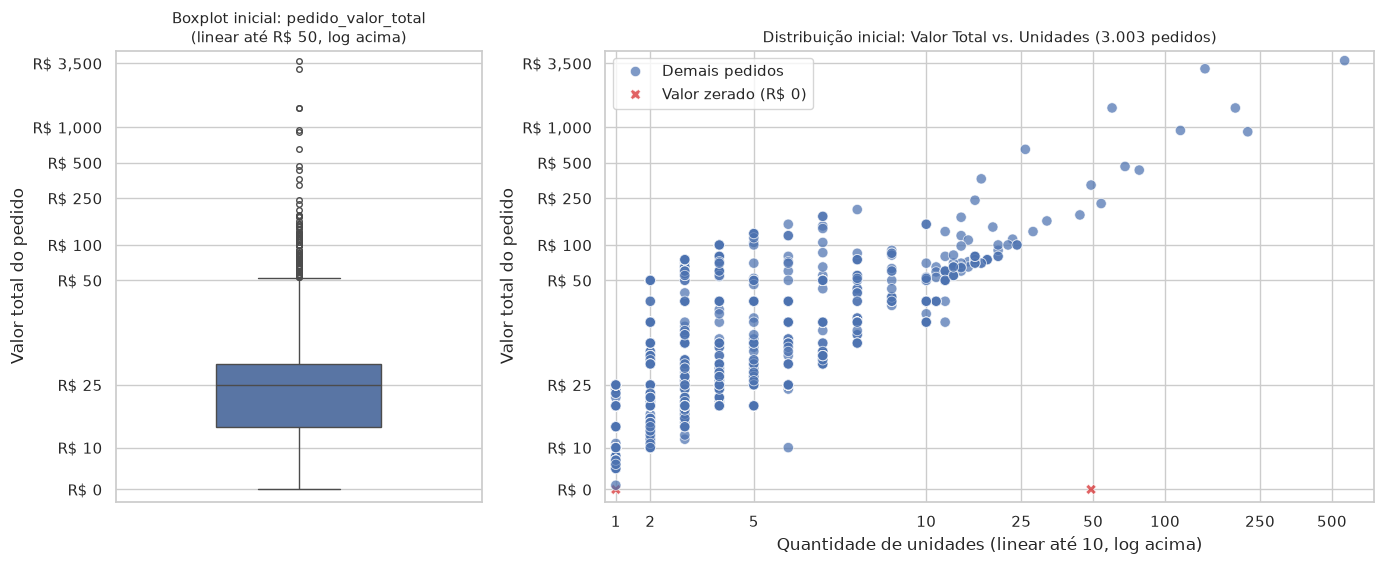

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import VarianceThreshold

sns.set_theme(style="whitegrid")

# Visualização inicial da distribuição bruta (3.003 pedidos) — antes de qualquer remoção
ticks_valor = [0, 10, 25, 50, 100, 250, 500, 1000, 3500]
ticks_unid = [1, 2, 5, 10, 25, 50, 100, 250, 500]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"width_ratios": [1, 2.1]})

# Painel 1: Boxplot de pedido_valor_total (faixa 0..50 linear + cauda em log)
sns.boxplot(y=df_pedidos["pedido_valor_total"], ax=axes[0], color="#4c72b0", width=0.45, fliersize=4)
axes[0].set_yscale("symlog", linthresh=50, linscale=1.6)
axes[0].set_yticks(ticks_valor)
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter("R$ {x:,.0f}"))
axes[0].set_ylim(-3, 4500)
axes[0].set_title("Boxplot inicial: pedido_valor_total\n(linear até R$ 50, log acima)", fontsize=11)
axes[0].set_ylabel("Valor total do pedido")

# Painel 2: Scatterplot qtd_unidades x pedido_valor_total destacando valores zerados
eh_zero = np.where(df_pedidos["pedido_valor_total"] <= 0, "Valor zerado (R$ 0)", "Demais pedidos")
sns.scatterplot(
    x=df_pedidos["qtd_unidades"],
    y=df_pedidos["pedido_valor_total"],
    hue=eh_zero,
    palette={"Demais pedidos": "#4c72b0", "Valor zerado (R$ 0)": "#d62728"},
    style=eh_zero,
    markers={"Demais pedidos": "o", "Valor zerado (R$ 0)": "X"},
    s=55,
    alpha=0.72,
    ax=axes[1],
)
axes[1].set_xscale("symlog", linthresh=10, linscale=1.3)
axes[1].set_yscale("symlog", linthresh=50, linscale=1.6)
axes[1].set_xticks(ticks_unid)
axes[1].xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}"))
axes[1].set_yticks(ticks_valor)
axes[1].yaxis.set_major_formatter(mticker.StrMethodFormatter("R$ {x:,.0f}"))
axes[1].set_xlim(0.7, 750)
axes[1].set_ylim(-3, 4500)
axes[1].set_title("Distribuição inicial: Valor Total vs. Unidades (3.003 pedidos)", fontsize=11)
axes[1].set_xlabel("Quantidade de unidades (linear até 10, log acima)")
axes[1].set_ylabel("Valor total do pedido")
axes[1].legend(frameon=True, loc="upper left")

plt.tight_layout()
plt.show()

Pedidos gratuitos removidos por regra de domínio (valor_total <= 0): 2


,evento_nome,pedido_subtotal,pedido_valor_total,qtd_unidades,qtd_itens,pagamento_digital
1260,São Francisco de Assis,915,0.0,49.0,2,0
2807,ExpoDireto,6,0.0,1.0,1,0


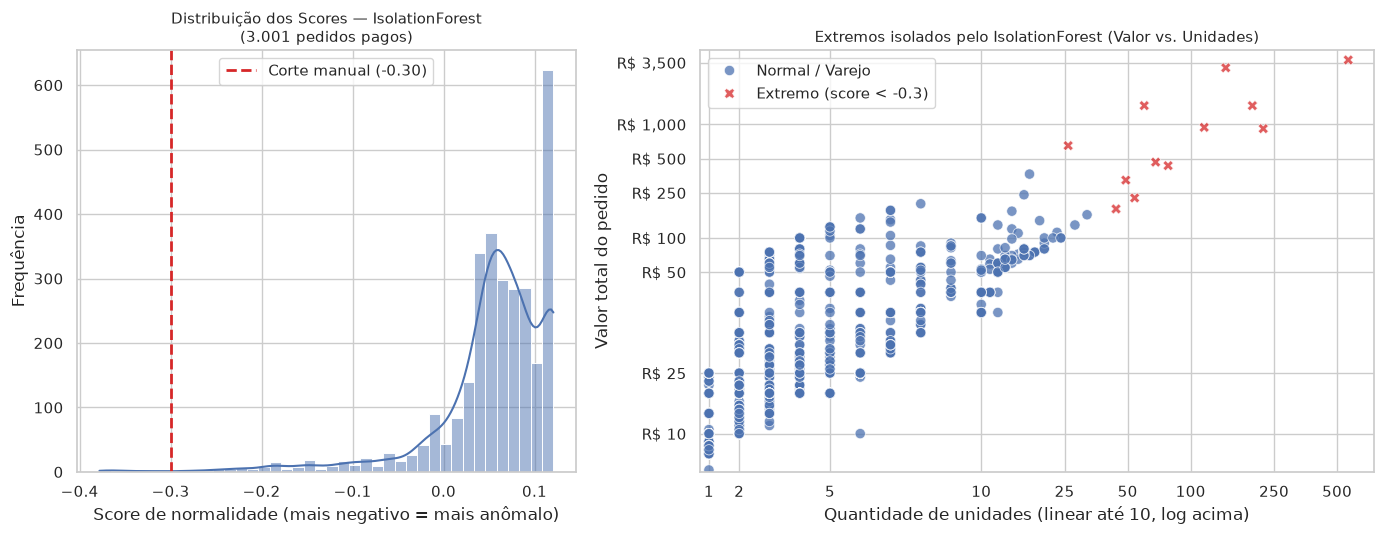

Eventos extremos removidos via IsolationForest (score < -0.3): 12 (0.40%)


,evento_nome,pedido_subtotal,pedido_valor_total,qtd_unidades,qtd_itens,pagamento_digital,iso_score
2672,Feira Polêsine,3696,3693.0,565.0,6,0,-0.3782
2942,Wolksfest Agudo,1462,1462.0,197.0,5,0,-0.3746
2903,ExpoSerra,3150,3150.0,147.0,3,0,-0.3734
2221,ExpoSerra,953,917.0,222.0,4,1,-0.3670
2859,Feira Polêsine,941,941.0,116.0,6,1,-0.3635
1177,Feira Polêsine,1463,1463.0,60.0,3,1,-0.3611
1227,ExpoSerra,465,465.0,68.0,6,1,-0.3518
2089,Feira Paraíso,433,433.0,78.0,4,0,-0.3490
1460,Feira Paraíso,323,323.0,49.0,5,1,-0.3330
1216,Expointer_2026,225,225.0,54.0,1,0,-0.3252


Base final pós-tratamento de outliers: 2989 pedidos (removidos: 2 gratuitos + 12 extremos = 14 pedidos, 0.47% da base).
Amplitude mantida (cauda natural tratada depois com PowerTransformer): Valor até R$ 365.00 | Unidades até 32


,pedidos,pct (%)
pagamento_digital,,
0,1782,59.62
1,1207,40.38


In [11]:
# 2. Regra de domínio: remover pedidos gratuitos (valor_total <= 0)
pedidos_gratuitos = df_pedidos[df_pedidos["pedido_valor_total"] <= 0][
    ["evento_nome", "pedido_subtotal", "pedido_valor_total", "qtd_unidades", "qtd_itens", "pagamento_digital"]
]
print(f"Pedidos gratuitos removidos por regra de domínio (valor_total <= 0): {len(pedidos_gratuitos)}")
display(pedidos_gratuitos)

df_pagos = df_pedidos[df_pedidos["pedido_valor_total"] > 0].copy().reset_index(drop=True)
assert len(pedidos_gratuitos) == 2
assert len(df_pagos) == 3001

# 3. IsolationForest sobre os 3.001 pedidos pagos usando decision_function (corte visual nos scores)
X_iso = StandardScaler().fit_transform(df_pagos[["pedido_valor_total", "qtd_unidades"]])
iso = IsolationForest(contamination="auto", random_state=42)
iso.fit(X_iso)
scores_iso = iso.decision_function(X_iso)

CORTE_SCORE = -0.30  # cauda extrema observada no histograma de scores
mask_extremo = scores_iso < CORTE_SCORE

# Visualização dos scores e dos extremos identificados
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.35]})

sns.histplot(scores_iso, bins=40, kde=True, color="#4c72b0", ax=axes[0])
axes[0].axvline(CORTE_SCORE, color="#d62728", linestyle="--", linewidth=2, label=f"Corte manual ({CORTE_SCORE:.2f})")
axes[0].set_title("Distribuição dos Scores — IsolationForest\n(3.001 pedidos pagos)", fontsize=11)
axes[0].set_xlabel("Score de normalidade (mais negativo = mais anômalo)")
axes[0].set_ylabel("Frequência")
axes[0].legend(frameon=True)

status_iso = np.where(mask_extremo, f"Extremo (score < {CORTE_SCORE})", "Normal / Varejo")
sns.scatterplot(
    x=df_pagos["qtd_unidades"],
    y=df_pagos["pedido_valor_total"],
    hue=status_iso,
    palette={"Normal / Varejo": "#4c72b0", f"Extremo (score < {CORTE_SCORE})": "#d62728"},
    style=status_iso,
    markers={"Normal / Varejo": "o", f"Extremo (score < {CORTE_SCORE})": "X"},
    s=55,
    alpha=0.75,
    ax=axes[1],
)
axes[1].set_xscale("symlog", linthresh=10, linscale=1.3)
axes[1].set_yscale("symlog", linthresh=50, linscale=1.6)
axes[1].set_xticks(ticks_unid)
axes[1].xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:.0f}"))
axes[1].set_yticks(ticks_valor)
axes[1].yaxis.set_major_formatter(mticker.StrMethodFormatter("R$ {x:,.0f}"))
axes[1].set_xlim(0.7, 750)
axes[1].set_ylim(0.5, 4500)
axes[1].set_title("Extremos isolados pelo IsolationForest (Valor vs. Unidades)", fontsize=11)
axes[1].set_xlabel("Quantidade de unidades (linear até 10, log acima)")
axes[1].set_ylabel("Valor total do pedido")
axes[1].legend(frameon=True, loc="upper left")

plt.tight_layout()
plt.show()

# Exibir os extremos removidos e aplicar Estratégia 1 (Trimming)
extremos_removidos = df_pagos.loc[
    mask_extremo,
    ["evento_nome", "pedido_subtotal", "pedido_valor_total", "qtd_unidades", "qtd_itens", "pagamento_digital"],
].assign(iso_score=np.round(scores_iso[mask_extremo], 4)).sort_values("iso_score")

print(f"Eventos extremos removidos via IsolationForest (score < {CORTE_SCORE}): {len(extremos_removidos)} ({len(extremos_removidos)/len(df_pagos)*100:.2f}%)")
display(extremos_removidos)

df_varejo = df_pagos.loc[~mask_extremo].copy().reset_index(drop=True)

assert len(extremos_removidos) == 12
assert len(df_varejo) == 2989

print(
    f"Base final pós-tratamento de outliers: {len(df_varejo)} pedidos "
    f"(removidos: 2 gratuitos + 12 extremos = 14 pedidos, {14/len(df_pedidos)*100:.2f}% da base)."
)
print(
    f"Amplitude mantida (cauda natural tratada depois com PowerTransformer): "
    f"Valor até R$ {df_varejo['pedido_valor_total'].max():.2f} | Unidades até {int(df_varejo['qtd_unidades'].max())}"
)
display(
    pd.DataFrame({
        "pedidos": df_varejo["pagamento_digital"].value_counts().sort_index(),
        "pct (%)": (df_varejo["pagamento_digital"].value_counts(normalize=True).sort_index() * 100).round(2),
    })
)

### 3.2 Diagnóstico de assimetria, escala e categóricas

Teste diagnóstico **em cópia** (sem alterar `df_varejo`) para definir o `ColumnTransformer`:
- **`PowerTransformer (Yeo-Johnson)`:** `pedido_valor_total` e `qtd_unidades` (normalizam bem, $\lambda \in [-5, 5]$).
- **`StandardScaler`:** `qtd_itens` (discreta `1..6`, $\lambda = -9{,}41$) e `hora_sin`/`hora_cos` (preservar ciclo 24h).
- **`OrdinalEncoder`:** `turno` (`Manhã < Tarde < Noite`).
- **`OneHotEncoder(min_frequency=0.05)`:** `evento_nome` (`7` feiras principais + `7` raras agrupadas).

In [12]:
from sklearn.preprocessing import PowerTransformer

# 1. Diagnóstico de assimetria e escala (teste de PowerTransformer apenas em cópia)
num_diag = ["pedido_valor_total", "qtd_unidades", "qtd_itens", "hora_sin", "hora_cos"]
pt_diag = PowerTransformer(method="yeo-johnson")
df_yj_copia = pd.DataFrame(pt_diag.fit_transform(df_varejo[num_diag]), columns=num_diag)

resumo_num = pd.DataFrame({
    "valores_unicos": df_varejo[num_diag].nunique(),
    "min": df_varejo[num_diag].min().round(2),
    "mediana": df_varejo[num_diag].median().round(2),
    "max": df_varejo[num_diag].max().round(2),
    "skew_antes": df_varejo[num_diag].skew().round(2),
    "skew_apos_YJ": df_yj_copia.skew().round(2),
    "lambda_YJ": np.round(pt_diag.lambdas_, 2),
    "tratamento_previsto": [
        "PowerTransformer (Yeo-Johnson)",
        "PowerTransformer (Yeo-Johnson)",
        "StandardScaler",
        "StandardScaler",
        "StandardScaler",
    ],
    "justificativa": [
        "Cauda contínua; normaliza bem (lambda em [-5, 5])",
        "Cauda ampla; reduz bem assimetria (lambda em [-5, 5])",
        "Discreta curta (1..6, 79% = 1); lambda fora de [-5, 5]",
        "Coordenada cíclica [-1, 1]; preservar geometria do relógio",
        "Coordenada cíclica [-1, 1]; preservar geometria do relógio",
    ],
})
print("Diagnóstico de assimetria e escala em cópia (df_varejo permanece inalterado):")
display(resumo_num)

# 2. Categórica ordinal: turno
ordem_turno = ["Manhã", "Tarde", "Noite"]
assert set(df_varejo["turno"].unique()) == set(ordem_turno)
print("Turno (ordem ordinal confirmada):", ordem_turno)
display(df_varejo["turno"].value_counts().reindex(ordem_turno).to_frame("pedidos"))

# 3. Categórica nominal: evento_nome e corte de categorias raras (< 5%)
ev_freq = pd.DataFrame({
    "pedidos": df_varejo["evento_nome"].value_counts(),
    "pct (%)": (df_varejo["evento_nome"].value_counts(normalize=True) * 100).round(2),
})
ev_freq["regra_5pct"] = np.where(ev_freq["pct (%)"] >= 5.0, "Manter (>= 5%)", "Agrupar em Outros (< 5%)")
print(
    f"Feiras em df_varejo: {len(ev_freq)} total | "
    f"{(ev_freq['pct (%)'] >= 5.0).sum()} principais (>= 5%) e {(ev_freq['pct (%)'] < 5.0).sum()} raras (< 5%)."
)
display(ev_freq)

Diagnóstico de assimetria e escala em cópia (df_varejo permanece inalterado):


,valores_unicos,min,mediana,max,skew_antes,skew_apos_YJ,lambda_YJ,tratamento_previsto,justificativa
pedido_valor_total,86,1.0,25.00,365.00,3.98,0.00,0.02,PowerTransformer (Yeo-Johnson),"Cauda contínua; normaliza bem (lambda em [-5, 5])"
qtd_unidades,25,1.0,2.00,32.00,3.20,0.33,-1.18,PowerTransformer (Yeo-Johnson),Cauda ampla; reduz bem assimetria (lambda em [...
qtd_itens,6,1.0,1.00,6.00,2.55,1.42,-9.41,StandardScaler,"Discreta curta (1..6, 79% = 1); lambda fora de..."
hora_sin,16,-1.0,-0.71,0.97,1.08,0.42,-0.65,StandardScaler,"Coordenada cíclica [-1, 1]; preservar geometri..."
hora_cos,15,-1.0,-0.71,0.87,1.14,0.33,-0.62,StandardScaler,"Coordenada cíclica [-1, 1]; preservar geometri..."


Turno (ordem ordinal confirmada): ['Manhã', 'Tarde', 'Noite']


,pedidos
turno,
Manhã,458
Tarde,2012
Noite,519


Feiras em df_varejo: 14 total | 7 principais (>= 5%) e 7 raras (< 5%).


,pedidos,pct (%),regra_5pct
evento_nome,,,
Expointer_2026,589,19.71,Manter (>= 5%)
Expo Afubra,511,17.10,Manter (>= 5%)
Festa do Moranguinho,381,12.75,Manter (>= 5%)
Wolksfest Agudo,329,11.01,Manter (>= 5%)
ExpoDireto,328,10.97,Manter (>= 5%)
EXPOBENTO,222,7.43,Manter (>= 5%)
ExpoRestinga,184,6.16,Manter (>= 5%)
FENAROZ,137,4.58,Agrupar em Outros (< 5%)
Expo Silveira Martins,115,3.85,Agrupar em Outros (< 5%)


### 3.3 Seleção de variáveis (Spearman e Variância Quase Nula)

- **Multicolinearidade (Spearman, robusta à assimetria):** remove `pedido_subtotal` ($\rho = 0{,}997$), `hora` ($-0{,}945$/$0{,}864$) e `dia_semana` ($0{,}882$). Mantém o par cíclico `hora_sin × hora_cos`.
- **Variância Quase Nula (`threshold=0.01`):** remove `tem_pao` (`0,30%` dos pedidos, variância `0,0030`).

Pares com correlação de Spearman alta (|rho| >= 0,80):


,var_1,var_2,spearman_rho
0,pedido_valor_total,pedido_subtotal,0.997
1,hora,hora_sin,-0.945
2,hora,hora_cos,0.864
3,dia_semana,eh_fim_de_semana,0.882
4,hora_sin,hora_cos,-0.808


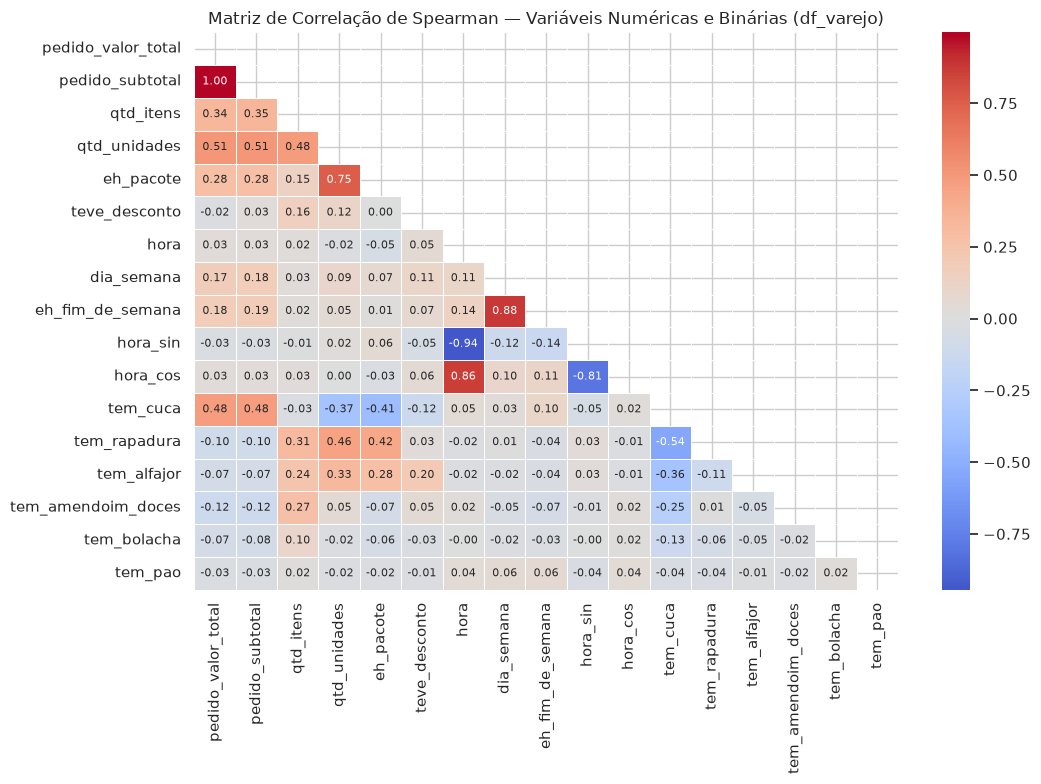

Colunas reprovadas no VarianceThreshold(0.01): ['tem_pao']


,frequencia_1 (%),variancia,mantida (var >= 0.01)
eh_fim_de_semana,47.71,0.2495,True
eh_pacote,26.53,0.1949,True
teve_desconto,6.26,0.0586,True
tem_cuca,51.32,0.2498,True
tem_rapadura,35.26,0.2283,True
tem_alfajor,16.56,0.1382,True
tem_amendoim_doces,9.33,0.0846,True
tem_bolacha,3.38,0.0326,True
tem_pao,0.30,0.0030,False


In [13]:
# 1. Matriz de correlação de Spearman (robusta à assimetria/não-normalidade)
cols_corr = [
    "pedido_valor_total", "pedido_subtotal", "qtd_itens", "qtd_unidades",
    "eh_pacote", "teve_desconto", "hora", "dia_semana", "eh_fim_de_semana",
    "hora_sin", "hora_cos", "tem_cuca", "tem_rapadura", "tem_alfajor",
    "tem_amendoim_doces", "tem_bolacha", "tem_pao",
]
corr = df_varejo[cols_corr].corr(method="spearman")

pares_altos = []
for i in range(len(cols_corr)):
    for j in range(i + 1, len(cols_corr)):
        rho = corr.iloc[i, j]
        if abs(rho) >= 0.80:
            pares_altos.append({"var_1": cols_corr[i], "var_2": cols_corr[j], "spearman_rho": round(rho, 3)})

print("Pares com correlação de Spearman alta (|rho| >= 0,80):")
display(pd.DataFrame(pares_altos))

plt.figure(figsize=(11, 8))
mask_tri = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask_tri, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.4, annot_kws={"size": 8})
plt.title("Matriz de Correlação de Spearman — Variáveis Numéricas e Binárias (df_varejo)")
plt.tight_layout()
plt.show()

# 2. Variância Quase Nula nas variáveis binárias (limiar 1% = 0.01)
cols_bin = [
    "eh_fim_de_semana", "eh_pacote", "teve_desconto",
    "tem_cuca", "tem_rapadura", "tem_alfajor",
    "tem_amendoim_doces", "tem_bolacha", "tem_pao",
]
vt = VarianceThreshold(threshold=0.01)
vt.fit(df_varejo[cols_bin])

resumo_vt = pd.DataFrame({
    "frequencia_1 (%)": (df_varejo[cols_bin].mean() * 100).round(2),
    "variancia": vt.variances_.round(4),
    "mantida (var >= 0.01)": vt.get_support(),
}, index=cols_bin)

removidas_vt = resumo_vt.index[~resumo_vt["mantida (var >= 0.01)"]].tolist()
assert removidas_vt == ["tem_pao"]

print(f"Colunas reprovadas no VarianceThreshold(0.01): {removidas_vt}")
display(resumo_vt)

### 3.4 Base selecionada (`df_model`)

Remove `pedido_id` e as `4` colunas descartadas $\rightarrow$ **`2.989` pedidos × `15` features + alvo** (`0` nulos).

In [14]:
colunas_descartar = ["pedido_id", "pedido_subtotal", "dia_semana", "hora", "tem_pao"]
df_model = df_varejo.drop(columns=colunas_descartar).copy()

assert df_model.shape == (2989, 16)
assert df_model.isna().sum().sum() == 0
assert set(df_model["pagamento_digital"].unique()) == {0, 1}

print(f"df_model pronto: {df_model.shape[0]} linhas x {df_model.shape[1]} colunas (15 features + 1 alvo) | Nulos: 0")
print("Colunas finais:", df_model.columns.tolist())
display(df_model.head())

df_model pronto: 2989 linhas x 16 colunas (15 features + 1 alvo) | Nulos: 0
Colunas finais: ['evento_nome', 'pedido_valor_total', 'qtd_itens', 'qtd_unidades', 'eh_pacote', 'teve_desconto', 'eh_fim_de_semana', 'hora_sin', 'hora_cos', 'turno', 'tem_cuca', 'tem_rapadura', 'tem_alfajor', 'tem_amendoim_doces', 'tem_bolacha', 'pagamento_digital']


,evento_nome,pedido_valor_total,qtd_itens,qtd_unidades,eh_pacote,teve_desconto,eh_fim_de_semana,hora_sin,hora_cos,turno,tem_cuca,tem_rapadura,tem_alfajor,tem_amendoim_doces,tem_bolacha,pagamento_digital
0,Expointer_2026,15.0,1,1.0,0,0,0,-0.965926,0.258819,Noite,1,0,0,0,0,0
1,Expointer_2026,100.0,1,4.0,0,0,0,-0.965926,-0.258819,Tarde,1,0,0,0,0,1
2,Expo Afubra,15.0,1,1.0,0,0,0,-0.258819,-0.965926,Tarde,1,0,0,0,0,1
3,ExpoDireto,6.0,1,1.0,0,0,0,-0.258819,-0.965926,Tarde,0,0,1,0,0,1
4,ExpoDireto,12.0,1,2.0,0,0,0,-0.866025,-0.500000,Tarde,0,0,1,0,0,0


## Etapa 4 — Split Estratificado e `Pipeline` + `ColumnTransformer`

Separa **Treino (80% = `2.391`)** e **Teste (20% = `598`)** com `stratify=y` **antes** de qualquer `.fit()` (zero *data leakage*).

In [15]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler

# 1. Definição explícita de X (15 features) e y (alvo binário)
FEATURES_X = [
    "evento_nome",
    "pedido_valor_total",
    "qtd_itens",
    "qtd_unidades",
    "eh_pacote",
    "teve_desconto",
    "eh_fim_de_semana",
    "hora_sin",
    "hora_cos",
    "turno",
    "tem_cuca",
    "tem_rapadura",
    "tem_alfajor",
    "tem_amendoim_doces",
    "tem_bolacha",
]
TARGET_Y = "pagamento_digital"

X = df_model[FEATURES_X].copy()
y = df_model[TARGET_Y].copy()

# 2. Split estratificado 80/20 ANTES de qualquer fit/transform
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

assert len(X_train) == 2391 and len(X_test) == 598
assert set(X_train.index).isdisjoint(set(X_test.index))
assert abs(y_train.mean() - y_test.mean()) < 0.01

resumo_split = pd.DataFrame({
    "pedidos": [len(y), len(y_train), len(y_test)],
    "pct_total (%)": [100.0, round(len(y_train) / len(y) * 100, 2), round(len(y_test) / len(y) * 100, 2)],
    "pct_digital (%)": [round(y.mean() * 100, 2), round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["Total (df_model)", "Treino (80%)", "Teste (20%)"])

print(f"X: {X.shape[1]} features | y: {TARGET_Y}")
display(resumo_split)

X: 15 features | y: pagamento_digital


,pedidos,pct_total (%),pct_digital (%)
Total (df_model),2989,100.00,40.38
Treino (80%),2391,79.99,40.40
Teste (20%),598,20.01,40.30


### 4.1 `ColumnTransformer` (`preprocessor`) e `criar_pipeline`

Empacota os 5 grupos de colunas em paralelo (mantendo `SimpleImputer` como blindagem para dados futuros) dentro de `Pipeline`.

In [16]:
skewed_features = ["pedido_valor_total", "qtd_unidades"]
numeric_features = ["qtd_itens", "hora_sin", "hora_cos"]
binary_features = [
    "eh_fim_de_semana", "eh_pacote", "teve_desconto",
    "tem_cuca", "tem_rapadura", "tem_alfajor",
    "tem_amendoim_doces", "tem_bolacha",
]
ordinal_features = ["turno"]
categorical_features = ["evento_nome"]

# Garantir cobertura exata das 15 colunas de X sem duplicatas nem omissões
todas_cols = skewed_features + numeric_features + binary_features + ordinal_features + categorical_features
assert len(todas_cols) == len(set(todas_cols)) == X.shape[1]
assert set(todas_cols) == set(X.columns)

skewed_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson")),  # standardize=True por padrão (média 0, std 1)
])

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

binary_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
])

ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(categories=[["Manhã", "Tarde", "Noite"]])),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.05, sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("skew", skewed_transformer, skewed_features),
        ("num", numeric_transformer, numeric_features),
        ("bin", binary_transformer, binary_features),
        ("ord", ordinal_transformer, ordinal_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

def criar_pipeline(modelo):
    return Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", modelo),
    ])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skew', ...), ('num', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transforme

### 4.2 Teste de integridade (zero *data leakage*)

Valida uma cópia (`clone`) com `fit_transform` só em `X_train` e `transform` em `X_test`: `15 -> 22` features, `0` nulos e escala padronizada.

In [17]:
prep_check = clone(preprocessor)
X_train_t = prep_check.fit_transform(X_train)
X_test_t = prep_check.transform(X_test)
feature_names_out = prep_check.get_feature_names_out()

# Asserts de integridade
assert not np.isnan(X_train_t).any() and not np.isnan(X_test_t).any()
assert X_train_t.shape[1] == X_test_t.shape[1] == len(feature_names_out)

df_train_t = pd.DataFrame(X_train_t, columns=feature_names_out, index=X_train.index)

# Conferir média ~ 0 e std ~ 1 nas variáveis padronizadas no treino
for col in ["pedido_valor_total", "qtd_unidades"]:
    assert abs(df_train_t[col].mean()) < 1e-6
    assert abs(df_train_t[col].std(ddof=0) - 1.0) < 1e-6

print(f"Colunas antes do preprocessor : {X_train.shape[1]}")
print(f"Colunas depois do preprocessor: {X_train_t.shape[1]} (X_train_t={X_train_t.shape}, X_test_t={X_test_t.shape})")
print("Nomes finais das features:", list(feature_names_out))

print("\nEstatísticas no treino transformado (skewed + numeric):")
display(df_train_t[skewed_features + numeric_features].agg(["mean", "std", "min", "max"]).round(3))

print("Amostra do treino transformado:")
display(df_train_t.head().round(3))

Colunas antes do preprocessor : 15
Colunas depois do preprocessor: 22 (X_train_t=(2391, 22), X_test_t=(598, 22))
Nomes finais das features: ['pedido_valor_total', 'qtd_unidades', 'qtd_itens', 'hora_sin', 'hora_cos', 'eh_fim_de_semana', 'eh_pacote', 'teve_desconto', 'tem_cuca', 'tem_rapadura', 'tem_alfajor', 'tem_amendoim_doces', 'tem_bolacha', 'turno', 'evento_nome_EXPOBENTO', 'evento_nome_Expo Afubra', 'evento_nome_ExpoDireto', 'evento_nome_ExpoRestinga', 'evento_nome_Expointer_2026', 'evento_nome_Festa do Moranguinho', 'evento_nome_Wolksfest Agudo', 'evento_nome_infrequent_sklearn']

Estatísticas no treino transformado (skewed + numeric):


,pedido_valor_total,qtd_unidades,qtd_itens,hora_sin,hora_cos
mean,-0.000,0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000
min,-3.677,-0.988,-0.467,-0.974,-1.035
max,4.443,2.040,8.401,2.881,3.067


Amostra do treino transformado:


,pedido_valor_total,qtd_unidades,qtd_itens,hora_sin,hora_cos,eh_fim_de_semana,eh_pacote,teve_desconto,tem_cuca,tem_rapadura,tem_alfajor,tem_amendoim_doces,tem_bolacha,turno,evento_nome_EXPOBENTO,evento_nome_Expo Afubra,evento_nome_ExpoDireto,evento_nome_ExpoRestinga,evento_nome_Expointer_2026,evento_nome_Festa do Moranguinho,evento_nome_Wolksfest Agudo,evento_nome_infrequent_sklearn
2530,1.278,0.205,-0.467,0.479,-0.960,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
538,1.368,1.734,3.080,0.479,-0.960,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2462,2.362,1.979,1.306,0.006,-0.741,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1648,0.222,-0.988,-0.467,-0.974,1.163,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2806,0.222,-0.988,-0.467,-0.712,0.064,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## Etapa 5 — Baseline, Validação Cruzada e `GridSearchCV`

Avalia baselines e compara **4 modelos** apenas em `X_train` (`StratifiedKFold(5)`, métrica `roc_auc`).

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = "roc_auc"

# 1. Modelos Baseline (referência inicial sem tuning)
baselines = {
    "Dummy (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística (default)": LogisticRegression(max_iter=1000, random_state=42),
}

linhas_base = []
for nome, modelo in baselines.items():
    pipe = criar_pipeline(modelo)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    linhas_base.append({
        "modelo": nome,
        "roc_auc_cv_media": round(scores.mean(), 4),
        "roc_auc_cv_std": round(scores.std(), 4),
    })

print("Resultados Baseline (StratifiedKFold 5-fold em X_train):")
display(pd.DataFrame(linhas_base))

Resultados Baseline (StratifiedKFold 5-fold em X_train):


,modelo,roc_auc_cv_media,roc_auc_cv_std
0,Dummy (classe majoritária),0.5000,0.0000
1,Regressão Logística (default),0.6585,0.0301


### 5.1 Comparação dos 4 classificadores (`GridSearchCV`)

Testa **Regressão Logística**, **KNN**, **Random Forest** e **XGBoost** dentro de `criar_pipeline(...)` e escolhe o campeão pelo melhor `ROC-AUC` no CV.

In [19]:
modelos_grades = {
    "Regressão Logística": {
        "modelo": LogisticRegression(max_iter=1000, random_state=42),
        "grade": {
            "model__C": [0.1, 1.0, 10.0],
            "model__class_weight": [None, "balanced"],
        },
    },
    "KNN": {
        "modelo": KNeighborsClassifier(),
        "grade": {
            "model__n_neighbors": [5, 11, 21, 31],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
        },
    },
    "Random Forest": {
        "modelo": RandomForestClassifier(random_state=42, n_jobs=-1),
        "grade": {
            "model__n_estimators": [100, 300],
            "model__max_depth": [None, 6, 12],
            "model__min_samples_leaf": [1, 5],
            "model__class_weight": [None, "balanced"],
        },
    },
    "XGBoost": {
        "modelo": XGBClassifier(random_state=42, n_jobs=-1, eval_metric="logloss"),
        "grade": {
            "model__n_estimators": [100, 250],
            "model__max_depth": [3, 6],
            "model__learning_rate": [0.05, 0.1],
            "model__subsample": [0.8, 1.0],
        },
    },
}

melhores_modelos = {}
linhas_cv = []

for nome, cfg in modelos_grades.items():
    gs = GridSearchCV(
        estimator=criar_pipeline(cfg["modelo"]),
        param_grid=cfg["grade"],
        cv=cv,
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=True,
    )
    gs.fit(X_train, y_train)
    melhores_modelos[nome] = gs.best_estimator_

    idx_best = gs.best_index_
    auc_cv_mean = gs.cv_results_["mean_test_score"][idx_best]
    auc_cv_std = gs.cv_results_["std_test_score"][idx_best]
    auc_tr_mean = gs.cv_results_["mean_train_score"][idx_best]

    linhas_cv.append({
        "modelo": nome,
        "roc_auc_cv_media": round(auc_cv_mean, 4),
        "roc_auc_cv_std": round(auc_cv_std, 4),
        "roc_auc_treino": round(auc_tr_mean, 4),
        "gap_treino_cv": round(auc_tr_mean - auc_cv_mean, 4),
        "melhores_hiperparametros": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
    })

df_resultados_cv = pd.DataFrame(linhas_cv).sort_values("roc_auc_cv_media", ascending=False).reset_index(drop=True)

campeao_nome = df_resultados_cv.loc[0, "modelo"]
campeao_pipeline = melhores_modelos[campeao_nome]
campeao_grade = modelos_grades[campeao_nome]["grade"]

print(f"Modelo campeão no CV: {campeao_nome} (ROC-AUC CV = {df_resultados_cv.loc[0, 'roc_auc_cv_media']:.4f} ± {df_resultados_cv.loc[0, 'roc_auc_cv_std']:.4f})")
display(df_resultados_cv)

Modelo campeão no CV: XGBoost (ROC-AUC CV = 0.6660 ± 0.0253)


,modelo,roc_auc_cv_media,roc_auc_cv_std,roc_auc_treino,gap_treino_cv,melhores_hiperparametros
0,XGBoost,0.6660,0.0253,0.7443,0.0783,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."
1,Random Forest,0.6635,0.0237,0.7484,0.0849,"{'class_weight': 'balanced', 'max_depth': 6, '..."
2,Regressão Logística,0.6585,0.0301,0.6756,0.0171,"{'C': 1.0, 'class_weight': None}"
3,KNN,0.6423,0.0239,0.7238,0.0815,"{'n_neighbors': 21, 'p': 1, 'weights': 'uniform'}"


## Etapa 6 — Avaliação no Teste, Nested CV, SHAP e Salvamento

Avalia os modelos ajustados no conjunto de teste hold-out (`598` pedidos nunca vistos no treino).

Comparação ROC-AUC (CV vs. Teste Hold-Out):


,modelo,roc_auc_cv,roc_auc_teste,diferenca_cv_teste
0,Random Forest,0.6635,0.6550,0.0085
1,Regressão Logística,0.6585,0.6507,0.0078
2,XGBoost,0.6660,0.6485,0.0175
3,KNN,0.6423,0.6431,-0.0008



Classification Report — XGBoost (Conjunto de Teste):
              precision    recall  f1-score   support

Dinheiro (0)       0.66      0.82      0.73       357
 Digital (1)       0.58      0.37      0.45       241

    accuracy                           0.64       598
   macro avg       0.62      0.59      0.59       598
weighted avg       0.63      0.64      0.62       598



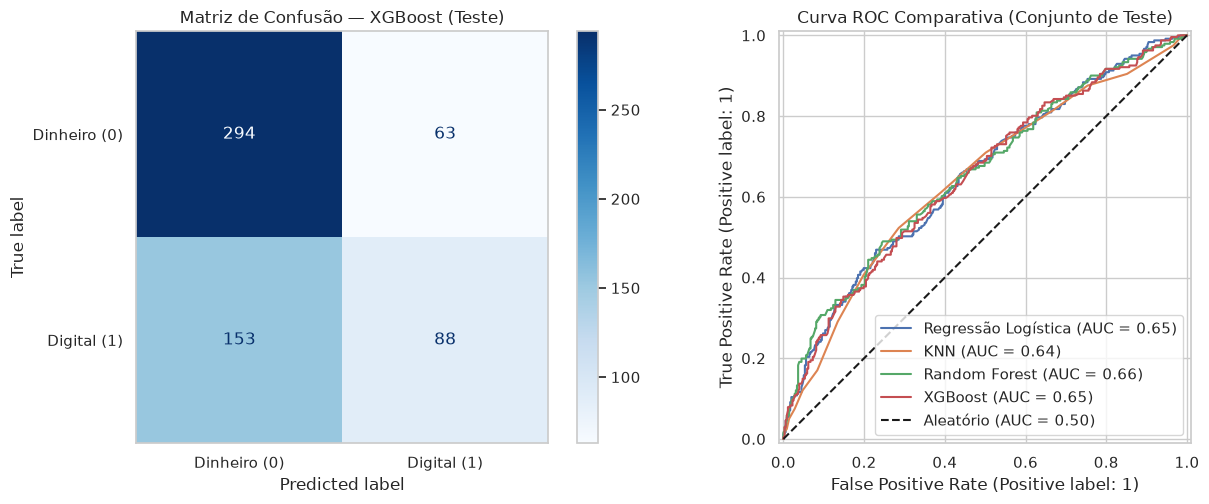

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report, roc_auc_score

# 1. Comparação ROC-AUC (CV vs Teste) para checar overfitting
linhas_teste = []
for nome, pipe in melhores_modelos.items():
    prob_test = pipe.predict_proba(X_test)[:, 1]
    auc_test = roc_auc_score(y_test, prob_test)
    auc_cv = df_resultados_cv.loc[df_resultados_cv["modelo"] == nome, "roc_auc_cv_media"].values[0]
    linhas_teste.append({
        "modelo": nome,
        "roc_auc_cv": auc_cv,
        "roc_auc_teste": round(auc_test, 4),
        "diferenca_cv_teste": round(auc_cv - auc_test, 4),
    })

df_teste = pd.DataFrame(linhas_teste).sort_values("roc_auc_teste", ascending=False).reset_index(drop=True)
print("Comparação ROC-AUC (CV vs. Teste Hold-Out):")
display(df_teste)

# 2. Classification Report do campeão no teste
y_pred_campeao = campeao_pipeline.predict(X_test)
print(f"\nClassification Report — {campeao_nome} (Conjunto de Teste):")
print(classification_report(y_test, y_pred_campeao, target_names=["Dinheiro (0)", "Digital (1)"]))

# 3. Matriz de Confusão do campeão + Curva ROC comparando os 4 modelos
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

ConfusionMatrixDisplay.from_estimator(
    campeao_pipeline,
    X_test,
    y_test,
    display_labels=["Dinheiro (0)", "Digital (1)"],
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title(f"Matriz de Confusão — {campeao_nome} (Teste)")
axes[0].grid(False)

for nome, pipe in melhores_modelos.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=nome, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Aleatório (AUC = 0.50)")
axes[1].set_title("Curva ROC Comparativa (Conjunto de Teste)")
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

### 6.1 Nested CV no campeão (Média $\pm$ IC 95%)

Validação cruzada aninhada (`5` folds externos × `3` internos) em `100%` dos dados para estimar o `ROC-AUC` real com margem de erro (IC 95%).

In [21]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

outer_scores = []
for fold, (tr_idx, te_idx) in enumerate(outer_cv.split(X, y), start=1):
    X_tr_out, X_te_out = X.iloc[tr_idx], X.iloc[te_idx]
    y_tr_out, y_te_out = y.iloc[tr_idx], y.iloc[te_idx]

    inner_search = GridSearchCV(
        estimator=criar_pipeline(modelos_grades[campeao_nome]["modelo"]),
        param_grid=campeao_grade,
        cv=inner_cv,
        scoring=SCORING,
        n_jobs=-1,
    )
    inner_search.fit(X_tr_out, y_tr_out)
    prob_out = inner_search.predict_proba(X_te_out)[:, 1]
    score_out = roc_auc_score(y_te_out, prob_out)
    outer_scores.append(score_out)
    print(f"Fold externo {fold}: ROC-AUC = {score_out:.4f}")

media_nested = np.mean(outer_scores)
std_nested = np.std(outer_scores, ddof=1)
ic95_nested = 1.96 * std_nested / np.sqrt(len(outer_scores))

print(f"\nNested CV ({campeao_nome}) — ROC-AUC: {media_nested:.4f} ± {ic95_nested:.4f} (IC 95%) | std = {std_nested:.4f}")

Fold externo 1: ROC-AUC = 0.6396
Fold externo 2: ROC-AUC = 0.6462
Fold externo 3: ROC-AUC = 0.6744
Fold externo 4: ROC-AUC = 0.6850
Fold externo 5: ROC-AUC = 0.6629

Nested CV (XGBoost) — ROC-AUC: 0.6616 ± 0.0166 (IC 95%) | std = 0.0189


### 6.2 Explicabilidade com SHAP

Usa `shap.TreeExplainer` no campeão (**XGBoost**) para mostrar quais features mais pesam e em qual direção (`+` = Digital, `-` = Dinheiro).

Importância média global das features (SHAP — barras):


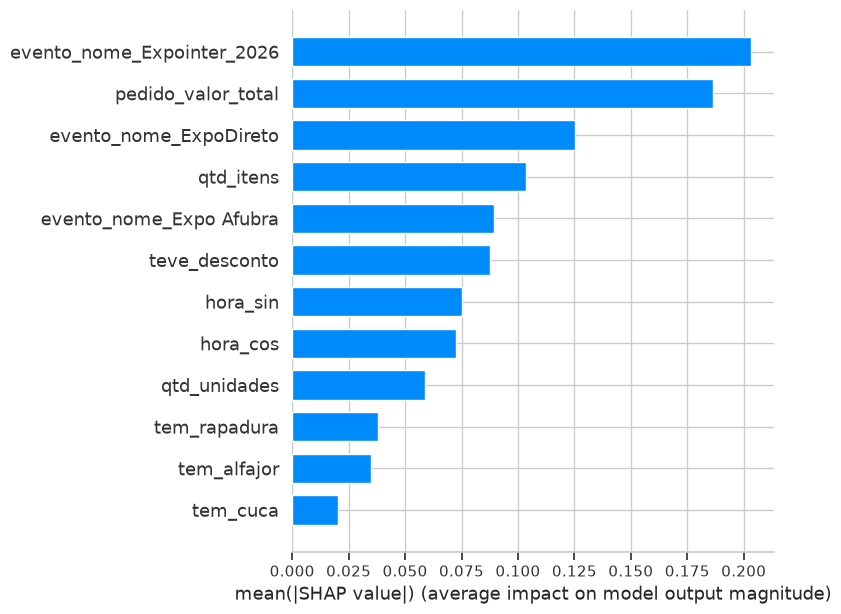

Impacto direcional por observação (SHAP — beeswarm):


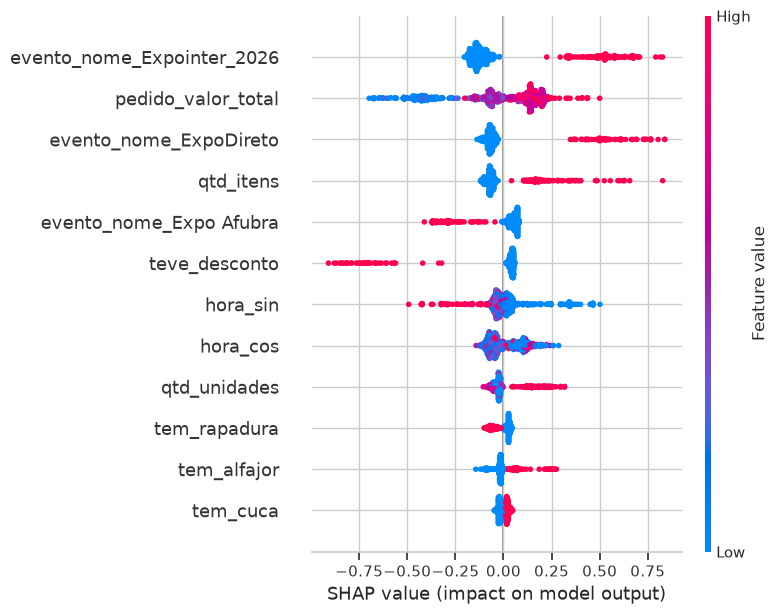

In [22]:
import shap

prep_campeao = campeao_pipeline.named_steps["preprocessor"]
modelo_campeao = campeao_pipeline.named_steps["model"]

X_test_shap = pd.DataFrame(
    prep_campeao.transform(X_test),
    columns=prep_campeao.get_feature_names_out(),
    index=X_test.index,
)

explainer = shap.TreeExplainer(modelo_campeao)
shap_values = explainer.shap_values(X_test_shap)

print("Importância média global das features (SHAP — barras):")
shap.summary_plot(shap_values, X_test_shap, plot_type="bar", max_display=12, show=True)

print("Impacto direcional por observação (SHAP — beeswarm):")
shap.summary_plot(shap_values, X_test_shap, max_display=12, show=True)

### 6.3 Retreino final, `joblib.dump` e exemplos práticos

Retreina o campeão em `100%` dos dados, salva `modelo_pagamento_digital_final.pkl`, valida o `joblib.load` e testa em `3` pedidos.

In [23]:
import joblib

final_search = GridSearchCV(
    estimator=criar_pipeline(modelos_grades[campeao_nome]["modelo"]),
    param_grid=campeao_grade,
    cv=cv,
    scoring=SCORING,
    n_jobs=-1,
)
final_search.fit(X, y)

caminho_modelo = "modelo_pagamento_digital_final.pkl"
joblib.dump(final_search.best_estimator_, caminho_modelo)


QTDE_EXEMPLOS = 10
# Validar carregamento e inferência em 3 exemplos práticos
modelo_carregado = joblib.load(caminho_modelo)
amostra = X_test.iloc[:QTDE_EXEMPLOS].copy()
probs = modelo_carregado.predict_proba(amostra)[:, 1]
preds = modelo_carregado.predict(amostra)

exemplos = amostra[["evento_nome", "pedido_valor_total", "qtd_itens", "teve_desconto", "turno"]].copy()
exemplos["prob_digital (%)"] = (probs * 100).round(1)
exemplos["previsto"] = np.where(preds == 1, "Digital", "Dinheiro")
exemplos["real"] = np.where(y_test.iloc[:QTDE_EXEMPLOS].values == 1, "Digital", "Dinheiro")

print(f"Pipeline final salvo e recarregado com sucesso: {caminho_modelo}")
print("Melhores hiperparâmetros finais (100% dos dados):", {k.replace("model__", ""): v for k, v in final_search.best_params_.items()})
display(exemplos)

Pipeline final salvo e recarregado com sucesso: modelo_pagamento_digital_final.pkl
Melhores hiperparâmetros finais (100% dos dados): {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


,evento_nome,pedido_valor_total,qtd_itens,teve_desconto,turno,prob_digital (%),previsto,real
1199,Wolksfest Agudo,50.0,1,0,Tarde,40.700001,Dinheiro,Dinheiro
1944,Expo Dona Francisca,15.0,1,0,Tarde,34.099998,Dinheiro,Dinheiro
1850,Festa do Moranguinho,25.0,1,0,Tarde,40.500000,Dinheiro,Dinheiro
2713,Expo Dona Francisca,7.0,1,0,Tarde,26.299999,Dinheiro,Dinheiro
526,Expo Afubra,25.0,1,0,Tarde,28.700001,Dinheiro,Digital
1510,Expo Silveira Martins,40.0,2,0,Noite,56.700001,Digital,Dinheiro
2965,Expointer_2026,25.0,1,0,Manhã,54.599998,Digital,Digital
1115,Expo Afubra,27.0,2,0,Tarde,48.000000,Dinheiro,Dinheiro
2988,Expo Silveira Martins,50.0,1,0,Tarde,37.799999,Dinheiro,Digital
289,Festa do Moranguinho,50.0,1,0,Tarde,41.200001,Dinheiro,Dinheiro


### 6.4 Conclusão

- **Desempenho estável sem *overfitting*:** campeão **XGBoost** com `ROC-AUC = 0,6616 ± 0,0166` (Nested CV, IC 95%) e empate técnico no teste hold-out (`~0,65`).
- **Principais fatores (SHAP):** **feira** (grandes feiras urbanas puxam para Digital), **valor total** (tickets maiores $\rightarrow$ Digital) e **desconto** (puxa para Dinheiro).
- **Limitação esperada:** `ROC-AUC ~0,66` é coerente no varejo presencial, pois a escolha do meio de pagamento também depende de fatores não observados (ex.: dinheiro disponível na carteira do cliente).

## Etapa 7 — Otimização Bayesiana com `Optuna` (Comparativo nos 4 Modelos)

Diferente do `GridSearchCV` (grade fixa), o **`Optuna`** aprende com as tentativas anteriores (TPE) para explorar espaços contínuos de hiperparâmetros. Abaixo rodamos `20` *trials* por modelo em `X_train` (`StratifiedKFold(5)`, `roc_auc`) e comparamos diretamente com o `GridSearchCV`.

In [24]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 20

def criar_modelo_optuna(nome, trial):
    if nome == "Regressão Logística":
        return LogisticRegression(
            C=trial.suggest_float("C", 0.01, 50.0, log=True),
            class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
            max_iter=1000,
            random_state=42,
        )
    if nome == "KNN":
        return KNeighborsClassifier(
            n_neighbors=trial.suggest_int("n_neighbors", 3, 45, step=2),
            weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
            p=trial.suggest_categorical("p", [1, 2]),
        )
    if nome == "Random Forest":
        return RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
            max_depth=trial.suggest_int("max_depth", 3, 15),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
            class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
            random_state=42,
            n_jobs=-1,
        )
    if nome == "XGBoost":
        return XGBClassifier(
            n_estimators=trial.suggest_int("n_estimators", 80, 300, step=20),
            max_depth=trial.suggest_int("max_depth", 2, 7),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            subsample=trial.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
            random_state=42,
            n_jobs=-1,
            eval_metric="logloss",
        )

linhas_optuna = []
melhores_optuna = {}

for nome in modelos_grades.keys():
    def objective(trial):
        pipe = criar_pipeline(criar_modelo_optuna(nome, trial))
        return cross_val_score(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1).mean()

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42),
    )
    study.optimize(objective, n_trials=N_TRIALS)

    best_pipe = criar_pipeline(criar_modelo_optuna(nome, study.best_trial))
    best_pipe.fit(X_train, y_train)
    melhores_optuna[nome] = best_pipe

    auc_test_opt = roc_auc_score(y_test, best_pipe.predict_proba(X_test)[:, 1])
    auc_cv_grid = df_resultados_cv.loc[df_resultados_cv["modelo"] == nome, "roc_auc_cv_media"].values[0]
    auc_test_grid = df_teste.loc[df_teste["modelo"] == nome, "roc_auc_teste"].values[0]

    linhas_optuna.append({
        "modelo": nome,
        "cv_grid": auc_cv_grid,
        "cv_optuna": round(study.best_value, 4),
        "ganho_cv": round(study.best_value - auc_cv_grid, 4),
        "teste_grid": auc_test_grid,
        "teste_optuna": round(auc_test_opt, 4),
        "melhores_params_optuna": study.best_params,
    })

df_optuna = pd.DataFrame(linhas_optuna).sort_values("cv_optuna", ascending=False).reset_index(drop=True)
print(f"Comparação GridSearchCV vs. Optuna ({N_TRIALS} trials por modelo):")
display(df_optuna)

Comparação GridSearchCV vs. Optuna (20 trials por modelo):


,modelo,cv_grid,cv_optuna,ganho_cv,teste_grid,teste_optuna,melhores_params_optuna
0,XGBoost,0.6660,0.6657,-0.0003,0.6485,0.6447,"{'n_estimators': 120, 'max_depth': 3, 'learnin..."
1,Random Forest,0.6635,0.6626,-0.0009,0.6550,0.6540,"{'n_estimators': 250, 'max_depth': 7, 'min_sam..."
2,Regressão Logística,0.6585,0.6585,0.0000,0.6507,0.6522,"{'C': 0.24289169469748878, 'class_weight': None}"
3,KNN,0.6423,0.6467,0.0044,0.6431,0.6472,"{'n_neighbors': 19, 'weights': 'uniform', 'p': 1}"
